In [1]:
%matplotlib inline 

In [2]:
import os
import io
import re
import itertools
import numpy as np
import pandas as pd
import json

In [64]:
data_sources = ['mnd_TSC']

distr_dims = ['-'.join(['Distancegroup', 'Timeperiodseq']),
              '-'.join(['Distancegroup', 'Legs'])]

aggr_levels = ['lsoa', 'msoa']
sample_sizes = ['sample_perc_10', 'sample_perc_20']

export = True
out_folder = r'./outputs'
tolerance = 0.01

run_info = list(itertools.product(data_sources, distr_dims, aggr_levels, sample_sizes))

In [65]:
def prepare_results_filepaths(run_results_fldr):
    flpaths = dict()
    flpaths['od'] = os.path.join(run_results_fldr, 'od_filtered.csv')
    flpaths['trs_obs_descr'] = os.path.join(run_results_fldr, 'trs_obs_descr.csv')
    flpaths['trs_obs_info'] = os.path.join(run_results_fldr, 'trs_obs_info.csv')
    flpaths['trs_mdl_descr'] = os.path.join(run_results_fldr, 'trs_mdl_descr.csv')
    flpaths['trs_mdl_info'] = os.path.join(run_results_fldr, 'trs_mdl_info.csv')
    flpaths['observed_distribution'] = os.path.join(run_results_fldr, 'target_distribution.csv')
    flpaths['optimisation_results'] = os.path.join(run_results_fldr, 'results.json')
    flpaths['trs_descr_comp'] = os.path.join(run_results_fldr, 'trs_descr_comp.csv')
    return flpaths

In [66]:
def prepare_od_from_tours(trs_info, trs_descr, od_dims, name='Trips'):
    times_used = trs_info.Timesused
    trs_descr = trs_descr.join(times_used)
    od = trs_descr.groupby(od_dims)['Timesused'].sum()
    od.name = name
    return od

In [67]:
def prepare_od_comparison(od_mdl, od_obs):
    od_obs.name = 'ObservedTrips'
    comp = od_obs.to_frame().join(od_mdl)
    comp.columns.name = 'TripsSource'
    comp = comp.stack()
    comp.name = 'Trips'
    return comp

In [68]:
def get_input_params_from_folder(infldr):
    fldrs = [name for name in os.listdir(infldr) if os.path.isdir(os.path.join(infldr, name))]
    inputs = []
    for fldr in fldrs:
        matches = re.findall('(\d+)legs-over(\d+)trips-distrConstr(\w+)', fldr)
        if matches:
            legs = int(matches[0][0])
            trips = int(matches[0][1])
            if matches[0][2] == 'True':
                distr_constr_enabled = True
            elif matches[0][2] == 'False':
                distr_constr_enabled = False
            else:
                raise ValueError('distrConstrEnabled must be either True or False')
                
            inputs.append([legs, trips, distr_constr_enabled])
        
    return inputs

In [76]:
def prepare_ditribution_comparison(trs_mdl_info, obs_distr):
    
    obs_distr.drop(columns=['Size'], inplace=True)

    optim_distr = trs_mdl_info.groupby('Distrgroupid')['Timesused'].sum()
    optim_distr = optim_distr.div(optim_distr.sum())
    optim_distr.name = 'Percentage'
    
    # We need to identify the distribution dimensions cols (should be all apart form the Percentage)
    idx_cols = list()
    for c in obs_distr.columns:
        if c != 'Percentage':
            idx_cols.append(c)
    
    obs_distr.set_index(idx_cols, append=True).squeeze()
    
    distr_comp = obs_distr['Percentage'].to_frame().join(optim_distr, rsuffix='_')
    distr_comp.columns = ['obs', 'mdl']
    distr_comp.columns.name = 'Type'
    distr_comp = distr_comp.stack('Type')
    distr_comp.name = 'Percentage'

    return distr_comp

In [77]:
def collapse_tour_legs(trs, leg_descr_cols, idx_cols=['Tourid']):
    seqs = list()
    for c in leg_descr_cols:
        seq = trs.groupby(level=idx_cols)[c].apply(tuple)
        seqs.append(seq)
    
    trs_collapsed = pd.concat(seqs, axis=1)
    
    return trs_collapsed

In [78]:
def include_run_info(df, d_run_params):
    try:
        df = df.to_frame()
    except AttributeError:
        pass
    
    for k, v in d_run_params.items():
        df[k] = v
        
    df.set_index(list(d_run_params.keys()), append=True, inplace=True)
    df = df.squeeze()
    return df

In [112]:
def compare_times_used(comp_descr, trs_obs_info, trs_mdl_info,
                       leg_descr_cols, idx_cols):
    
    trs_obs_info['Type'] = 'obs'
    trs_mdl_info['Type'] = 'mdl'
    
    trs_obs_info.set_index('Type', append=True, inplace=True)
    trs_mdl_info.set_index('Type', append=True, inplace=True)
    trs_obs_info = trs_obs_info.swaplevel()
    trs_mdl_info = trs_mdl_info.swaplevel()
    
    times_used = pd.concat([trs_obs_info['Timesused'], 
                            trs_mdl_info['Timesused']])

    df = collapse_tour_legs(comp_descr, leg_descr_cols, idx_cols)
    df = df.join(times_used)
    
    obs = df.xs('obs', level='Type', drop_level=False)
    mdl = df.xs('mdl', level='Type', drop_level=False)
    
    obs = obs.groupby(leg_descr_cols)['Timesused'].sum()
    mdl = mdl.groupby(leg_descr_cols)['Timesused'].sum()
    
    mrg = pd.merge(obs.to_frame(), mdl.to_frame(),
                   left_index=True, right_index=True,
                   suffixes=('_obs', '_mdl'))

    mrg.columns.name = 'Type'
    mrg.rename(columns=lambda x: x.replace('Timesused_', ''), inplace=True)
    mrg = mrg.stack()
    mrg.name = 'Timesused'

    df = mrg.unstack()
    df['Diff'] = df['obs'] - df['mdl']
    df['Diffabs'] = df['Diff'].abs()
    comp_times_used = df
    
    return comp_times_used

In [113]:
def prepare_run_info_dict(run_params):
    (data_source, distr_dims, aggr_level, sample_size,
     legs, trips_thresh, distr_constr_enabled) = run_params
    
    d_run_params = dict()
    d_run_params['DataSource'] = data_source
    d_run_params['AggrLevel'] = aggr_level
    d_run_params['SampleSize'] = sample_size
    d_run_params['DistrDims'] = distr_dims
    d_run_params['MaxLegs'] = int(legs)
    d_run_params['TripsThresh'] = int(trips_thresh)
    d_run_params['DistrConstr'] = distr_constr_enabled
    return d_run_params

In [114]:
def main(model_info):

    data_source, distr_dims, aggr_level, sample_size = model_info
    
    results_folder = r'../outputs/{}/{}/{}/{}'.format(data_source, distr_dims, aggr_level, sample_size)
    params = get_input_params_from_folder(results_folder)

    concat_od_mdl = list()
    concat_od_obs = list()

    concat_trs_mdl_used_descr = list()

    concat_comp_distrs = list()
    concat_comp_descrs = list()
    concat_comp_times_used = list()
    
    for legs, trips_thresh, distr_constr_enabled in params:
        print(aggr_level)
        print(legs, trips_thresh, distr_constr_enabled)
        run_info = model_info.copy()
        
        run_tmplt = '{}legs-over{}trips-distrConstr{}'.format(legs, trips_thresh, distr_constr_enabled)
        run_results_fldr = os.path.join(results_folder, run_tmplt)

        flpaths = prepare_results_filepaths(run_results_fldr)
        
        obs_distr = pd.read_csv(flpaths['observed_distribution'], index_col='Distrgroupid')

        trs_obs_info = pd.read_csv(flpaths['trs_obs_info'], index_col=['Tourid'])
        trs_obs_descr = pd.read_csv(flpaths['trs_obs_descr'], index_col=['Tourid', 'Legidx'])
    
        trs_mdl_info = pd.read_csv(flpaths['trs_mdl_info'], index_col=['Tourid'])
        trs_mdl_descr = pd.read_csv(flpaths['trs_mdl_descr'], index_col=['Tourid', 'Legidx'])
    
        od_dims = ['Source', 'Target', 'Purpose', 'Direction', 'Timeperiod']
        
        # For the observed tours prepare the od only for the high frequency tours
        trs_obs_info['Timesused'] = np.where(trs_obs_info['Inlowfreqgroup'], 0, 1)
        
        od_obs = prepare_od_from_tours(trs_obs_info, trs_obs_descr,
                                       od_dims=od_dims, name='ObservedTrips')
        
        od_mdl = prepare_od_from_tours(trs_mdl_info, trs_mdl_descr,
                                       od_dims=od_dims, name='ModelledTrips')
        
        if od_mdl is None:
            print('No results for legs:{}-trips:{}-distrConstr:{}'.format(legs, trips_thresh, distr_constr_enabled))
            continue

        comp_distr = prepare_ditribution_comparison(trs_mdl_info, obs_distr)

        #comp_descr = prepare_descr_comparison(trs_obs_descr, trs_mdl_descr,
        #                                      trs_mdl_info.Timesused, True)

        usecols = ['Type', 'Tourid', 'Legidx',
                   'Source', 'Target', 'Purpose', 'Direction', 'Timeperiod',
                   'Inboth']
        
        comp_descr = pd.read_csv(flpaths['trs_descr_comp'],
                                 usecols=usecols,
                                 index_col=['Type', 'Tourid', 'Legidx'])
        
        leg_descr_cols = ['Source', 'Timeperiod']
        idx_cols = ['Type', 'Tourid']
        
        comp_times_used = compare_times_used(comp_descr,
                                             trs_obs_info, trs_mdl_info,
                                             leg_descr_cols, idx_cols)
        
        run_info.extend([legs, trips_thresh, distr_constr_enabled])
        d_run_info = prepare_run_info_dict(run_info)
        
        od_obs = include_run_info(od_obs, d_run_info)
        od_mdl = include_run_info(od_mdl, d_run_info)
        comp_distr = include_run_info(comp_distr, d_run_info)
        comp_descr = include_run_info(comp_descr, d_run_info)
        comp_times_used = include_run_info(comp_times_used, d_run_info)
        
        concat_od_mdl.append(od_mdl)
        concat_od_obs.append(od_obs)
        concat_comp_descrs.append(comp_descr)
        concat_comp_distrs.append(comp_distr)
        concat_comp_times_used.append(comp_times_used)

    od_mdl = pd.concat(concat_od_mdl)
    od_obs = pd.concat(concat_od_obs)

    comp_ods = prepare_od_comparison(od_mdl, od_obs)
    comp_distrs = pd.concat(concat_comp_distrs)
    comp_descrs = pd.concat(concat_comp_descrs)
    comp_times_used = pd.concat(concat_comp_times_used)
    
    return comp_ods, comp_distrs, comp_descrs, comp_times_used

In [115]:
comparisons = dict()

ods = list()
distrs = list()
descrs = list()
times_used = list()

for ri in run_info:
    comp_ods, comp_distrs, comp_descrs, comp_times_used = main(list(ri))
    ods.append(comp_ods)
    distrs.append(comp_distrs)
    descrs.append(comp_descrs)
    times_used.append(comp_times_used)

comparisons['ods'] = pd.concat(ods)
comparisons['distrs'] = pd.concat(distrs)
comparisons['descrs'] = pd.concat(descrs)
comparisons['timesused'] = pd.concat(times_used)

if export:
    #mdl_nchains.to_csv(os.path.join(out_folder, 'optimisation_results.csv'), header=True, index=True)
    comparisons['ods'].to_csv(os.path.join(out_folder, 'comparison_od.csv'), header=True)
    comparisons['distrs'].to_csv(os.path.join(out_folder, 'comparison_distributions.csv'), header=True, index=True)
    comparisons['descrs'].to_csv(os.path.join(out_folder, 'comparison_descrs.csv'), header=True, index=True)
    comparisons['timesused'].to_csv(os.path.join(out_folder, 'comparison_times_used.csv'), header=True, index=True)

lsoa
5 1 False
lsoa
5 1 True
lsoa
5 1 False
lsoa
5 1 True
msoa
5 1 False
msoa
5 1 True
msoa
5 1 False


/home/harisbal/anaconda3/envs/phd/lib/python3.6/site-packages/numpy/lib/arraysetops.py:522: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  mask |= (ar1 == a)


msoa
5 1 True
lsoa
5 1 False
lsoa
5 1 True
lsoa
5 1 False
lsoa
5 1 True
msoa
5 1 False
msoa
5 1 True
msoa
5 1 False
msoa
5 1 True


In [117]:
df = comparisons['distrs'].copy()
df = df.xs(True, level='DistrConstr')
df = df.unstack('Type')
df['Diff_perc'] = df['obs'].sub(df['mdl'])

df['BelowTolerance'] = df.Diff_perc.abs() <= tolerance
df.dropna(inplace=True)
df['BelowTolerance'].all()

True

In [118]:
grpby_lvls = ['DataSource', 'DistrDims', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr',
              'TripsSource', 'Purpose']

df = comparisons['ods'].groupby(level=grpby_lvls).sum()

df = df.unstack('TripsSource')

df['Diff'] = df.ObservedTrips - df.ModelledTrips
df['Diff_perc'] = df.ModelledTrips/df.ObservedTrips - 1

df.style.format({
    'ModelledTrips': '{:,.0f}'.format,
    'ObservedTrips': '{:,.0f}'.format,
    'Diff': '{:,.0f}'.format,
    'Diff_perc': '{:.0%}'.format
})

In [129]:
filters = dict()
filters['DataSource'] = 'mnd_TSC'
filters['DistrDims'] = 'Distancegroup-Timeperiodseq'
filters['AggrLevel'] = 'lsoa'
filters['SampleSize'] = 'sample_perc_20'
filters['MaxLegs'] = 5
filters['TripsThresh'] = 1

In [130]:
if filters:
    comparisons_filt = dict()
    for k, f in comparisons.items():
        comparisons_filt[k] = comparisons[k].xs(list(filters.values()),
                                                level=list(filters.keys()))
    analysis_comp = comparisons_filt.copy()
else:
    analysis_comp = comparisons.copy()

False
True


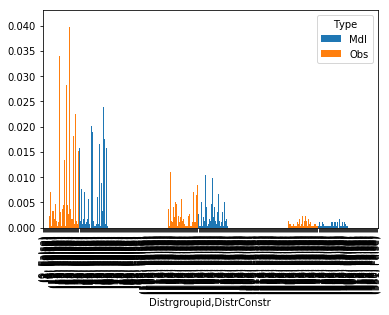

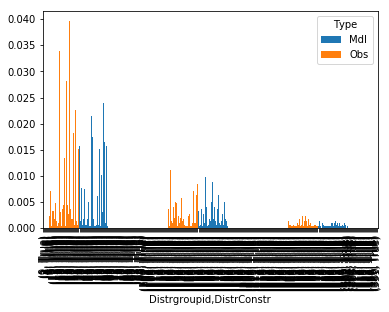

In [22]:
grpby_lvls = ['DataSource', 'AggrLevel', 'SampleSize',
              'MaxLegs', 'TripsThresh', 'DistrConstr']

grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]

dfg = analysis_comp['distrs'].groupby(level=grpby_lvls)
for k, g in dfg:
    print(k)
    plt = g.unstack('Type')
    plt.plot(kind='bar')

In [121]:
grpby_lvls = ['MaxLegs', 'TripsThresh', 'DistrConstr', 'Inboth']
grpby_lvls = [gl for gl in grpby_lvls if gl not in list(filters.keys())]

analysis_comp['descrs'].groupby(grpby_lvls).size().unstack('DistrConstr')

DistrConstr,False,True
Inboth,,
False,1198,1396
True,14832,14634


In [122]:
df = analysis_comp['descrs']#.xs(True, level='DistrConstr')

In [123]:
df.head(2)

Source     Target Purpose     Direction  \
Type Tourid Legidx DistrConstr                                               
mdl  74     0      False        E01014387  E01033345      HB      FromHome   
            1      False        E01033345  E01014395     NHB  NonHomeBased   

                               Timeperiod  Inboth  
Type Tourid Legidx DistrConstr                     
mdl  74     0      False               IP    True  
            1      False               IP    True

In [124]:
grpby_cols = ['DataSource', 'AggrLevel', 'SampleSize',
              'DistrDims', 'MaxLegs', 'TripsThresh', 'DistrConstr']

comparisons['timesused'].groupby(level=grpby_cols).sum()

Type                                                                                              obs  \
DataSource AggrLevel SampleSize     DistrDims                   MaxLegs TripsThresh DistrConstr         
mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs          5       1           False        2761   
                                                                                    True         2715   
                                    Distancegroup-Timeperiodseq 5       1           False        2780   
                                                                                    True         2747   
                     sample_perc_20 Distancegroup-Legs          5       1           False        3601   
                                                                                    True         3927   
                                    Distancegroup-Timeperiodseq 5       1           False        3628   
                                                                                    True         3687   
           msoa      sample_perc_10 Distancegroup-Legs          5       1           False        1479   
                                                                                    True         1466   
                                    Distancegroup-Timeperiodseq 5       1           False        1566   
                                                                                    True         1482   
                     sample_perc_20 Distancegroup-Legs          5       1           False        1889   
                                                                                    True         2070   
                                    Distancegroup-Timeperiodseq 5       1           False        1914   
                                                                                    True         1964   

Type                                                                                              mdl  \
DataSource AggrLevel SampleSize     DistrDims                   MaxLegs TripsThresh DistrConstr         
mnd_TSC    lsoa      sample_perc_10 Distancegroup-Legs          5       1           False        2761   
                                                                                    True         2716   
                                    Distancegroup-Timeperiodseq 5       1           False        2781   
                                                                                    True         2748   
                     sample_perc_20 Distancegroup-Legs          5       1           False        3619   
                                                                                    True         3947   
                                    Distancegroup-Timeperiodseq 5       1           False        3647   
                                                                                    True         3705   
           msoa      sample_perc_10 Distancegroup-Legs          5       1           False        1538   
                                                                                    True         1521   
                                    Distancegroup-Timeperiodseq 5       1           False        1625   
                                                                                    True         1529   
                     sample_perc_20 Distancegroup-Legs          5       1           False        2031   
                                                                                    True         2277   
                                    Distancegroup-Timeperiodseq 5       1           False        2099   
                                                                                    True         2102   

Type                                                                                             Diff  \
DataSource AggrLevel SampleSize     DistrDims                   MaxLegs TripsThresh DistrConstr         
mnd_TSC 

In [131]:
df = comparisons['timesused'].copy()
df

,,,,,,,,Type,obs,mdl,Diff,Diffabs
Source,Timeperiod,DataSource,AggrLevel,SampleSize,DistrDims,MaxLegs,TripsThresh,DistrConstr,,,,
"(E01014387, E01014377, E01014474)","(IP, IP, IP)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1,1,0,0
"(E01014387, E01014379)","(AM, PM)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1,1,0,0
"(E01014387, E01014410)","(PM, OP)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1,1,0,0
"(E01014387, E01014470)","(AM, AM)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1,1,0,0
"(E01014387, E01014531)","(AM, PM)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1,1,0,0
"(E01014387, E01014556)","(PM, OP)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1,1,0,0
"(E01014387, E01014994, E01014949)","(AM, IP, PM)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1,1,0,0
"(E01014387, E01033345, E01014395)","(IP, IP, IP)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1,1,0,0
"(E01014396, E01014403)","(AM, PM)",mnd_TSC,lsoa,sample_perc_10,Distancegroup-Timeperiodseq,5,1,False,1,1,0,0


In [134]:
df.obs

Source                                        Timeperiod        DataSource  AggrLevel  SampleSize      DistrDims                    MaxLegs  TripsThresh  DistrConstr
(E01014387, E01014377, E01014474)             (IP, IP, IP)      mnd_TSC     lsoa       sample_perc_10  Distancegroup-Timeperiodseq  5        1            False          1
(E01014387, E01014379)                        (AM, PM)          mnd_TSC     lsoa       sample_perc_10  Distancegroup-Timeperiodseq  5        1            False          1
(E01014387, E01014410)                        (PM, OP)          mnd_TSC     lsoa       sample_perc_10  Distancegroup-Timeperiodseq  5        1            False          1
(E01014387, E01014470)                        (AM, AM)          mnd_TSC     lsoa       sample_perc_10  Distancegroup-Timeperiodseq  5        1            False          1
(E01014387, E01014531)                        (AM, PM)          mnd_TSC     lsoa       sample_perc_10  Distancegroup-Timeperiodseq  5        1        